In [1]:
# Imports

import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.dataset as ds

In [2]:
# Load

dataset = ds.dataset(
    "data/weather.parquet",
    format="parquet"
)

table = dataset.to_table(
    columns=["time", "temperature_2m", "relative_humidity_2m"]
)

df = table.to_pandas()
df["time"] = df["time"].dt.tz_convert("America/Edmonton")

df = df.loc[df["time"].between("2026-06-01", "2026-09-01", inclusive="left")]

df.head()

,time,temperature_2m,relative_humidity_2m
231551,2026-06-01 00:00:00-06:00,5.0,90
231552,2026-06-01 01:00:00-06:00,5.0,90
231553,2026-06-01 02:00:00-06:00,5.0,89
231554,2026-06-01 03:00:00-06:00,5.0,90
231555,2026-06-01 04:00:00-06:00,4.7,93


In [3]:
# Inspect

# Structure
print(df["time"].min(), "to", df["time"].max(), "\n")
print("Shape:", df.shape, "\n")
print("Dtypes:")
print(df.dtypes, "\n")

# Missingness
print("Any Nulls:", df.isna().any().any(), "\n")

# Duplicates
print("Duplicate Rows:", df.duplicated().any())
print("Duplicate Times:", df["time"].duplicated().any(), "\n")

# Temporal Sanity
print("Non-Monotonic Times:", not df["time"].is_monotonic_increasing)
print("Unexpected Time Deltas:", df["time"].diff().dropna().ne(pd.Timedelta(hours = 1)).any(), "\n")

# Value Sanity
display(df[["temperature_2m", "relative_humidity_2m"]].describe().T)

2026-06-01 00:00:00-06:00 to 2026-08-31 23:00:00-06:00 

Shape: (2293, 3) 

Dtypes:
time                    datetime64[us, America/Edmonton]
temperature_2m                                   float64
relative_humidity_2m                               int64
dtype: object 

Any Nulls: False 

Duplicate Rows: True
Duplicate Times: True 

Non-Monotonic Times: False
Unexpected Time Deltas: True 



,count,mean,std,min,25%,50%,75%,max
temperature_2m,2293.0,16.461448,5.988231,4.1,12.0,15.4,20.7,34.1
relative_humidity_2m,2293.0,64.952028,22.088754,15.0,46.0,68.0,84.0,100.0


In [4]:
# Additional Inspect - Duplicate Rows and Duplicate Times count and %

duplicates = pd.DataFrame({"Duplicate Rows": df.duplicated(),
                           "Duplicate Times": df["time"].duplicated()
})

duplicate_summary = pd.DataFrame({"count": duplicates.sum(),
                                  "pct": duplicates.mean().mul(100).round(2).astype(str).add("%")
})

display(duplicate_summary)

,count,pct
Duplicate Rows,43,1.88%
Duplicate Times,85,3.71%


In [5]:
duplicate_df = (df.loc[df["time"].duplicated(keep = False)]
                  .sort_values("time"))

print("Affected Timestamps:", duplicate_df["time"].nunique())
print("Rows Involved:", len(duplicate_df))

display(duplicate_df.head(20))

Affected Timestamps: 85
Rows Involved: 170


,time,temperature_2m,relative_humidity_2m
231832,2026-06-12 17:00:00-06:00,11.1,72
231833,2026-06-12 17:00:00-06:00,11.1,72
231834,2026-06-12 18:00:00-06:00,11.6,69
231835,2026-06-12 18:00:00-06:00,13.6,69
231836,2026-06-12 19:00:00-06:00,11.7,65
231837,2026-06-12 19:00:00-06:00,11.7,65
231838,2026-06-12 20:00:00-06:00,11.1,65
231839,2026-06-12 20:00:00-06:00,11.1,65
231841,2026-06-12 21:00:00-06:00,12.3,69
231840,2026-06-12 21:00:00-06:00,10.3,69


In [6]:
variation = duplicate_df.groupby("time")[["temperature_2m", "relative_humidity_2m"]].nunique()

conflicts = variation.gt(1).any(axis = 1)

print("Conflicting Timestamps:", conflicts.sum())
print(f"Conflicting %: {conflicts.sum() / len(df):.2%}")

Conflicting Timestamps: 42
Conflicting %: 1.83%


In [7]:
affected = pd.DataFrame({"time": variation.index,
                         "conflicting": conflicts.to_numpy()
})

affected["month"] = affected["time"].dt.month
affected["daytime"] = affected["time"].dt.hour.between(8, 19)

monthly_distribution = (affected.loc[affected["daytime"]]
                                  .groupby("month")
                                  .agg(duplicate_hours = ("time", "size"),
                                       conflicting_hours = ("conflicting", "sum")))

display(monthly_distribution)

,duplicate_hours,conflicting_hours
month,,
6,15,10
7,12,6
8,16,11


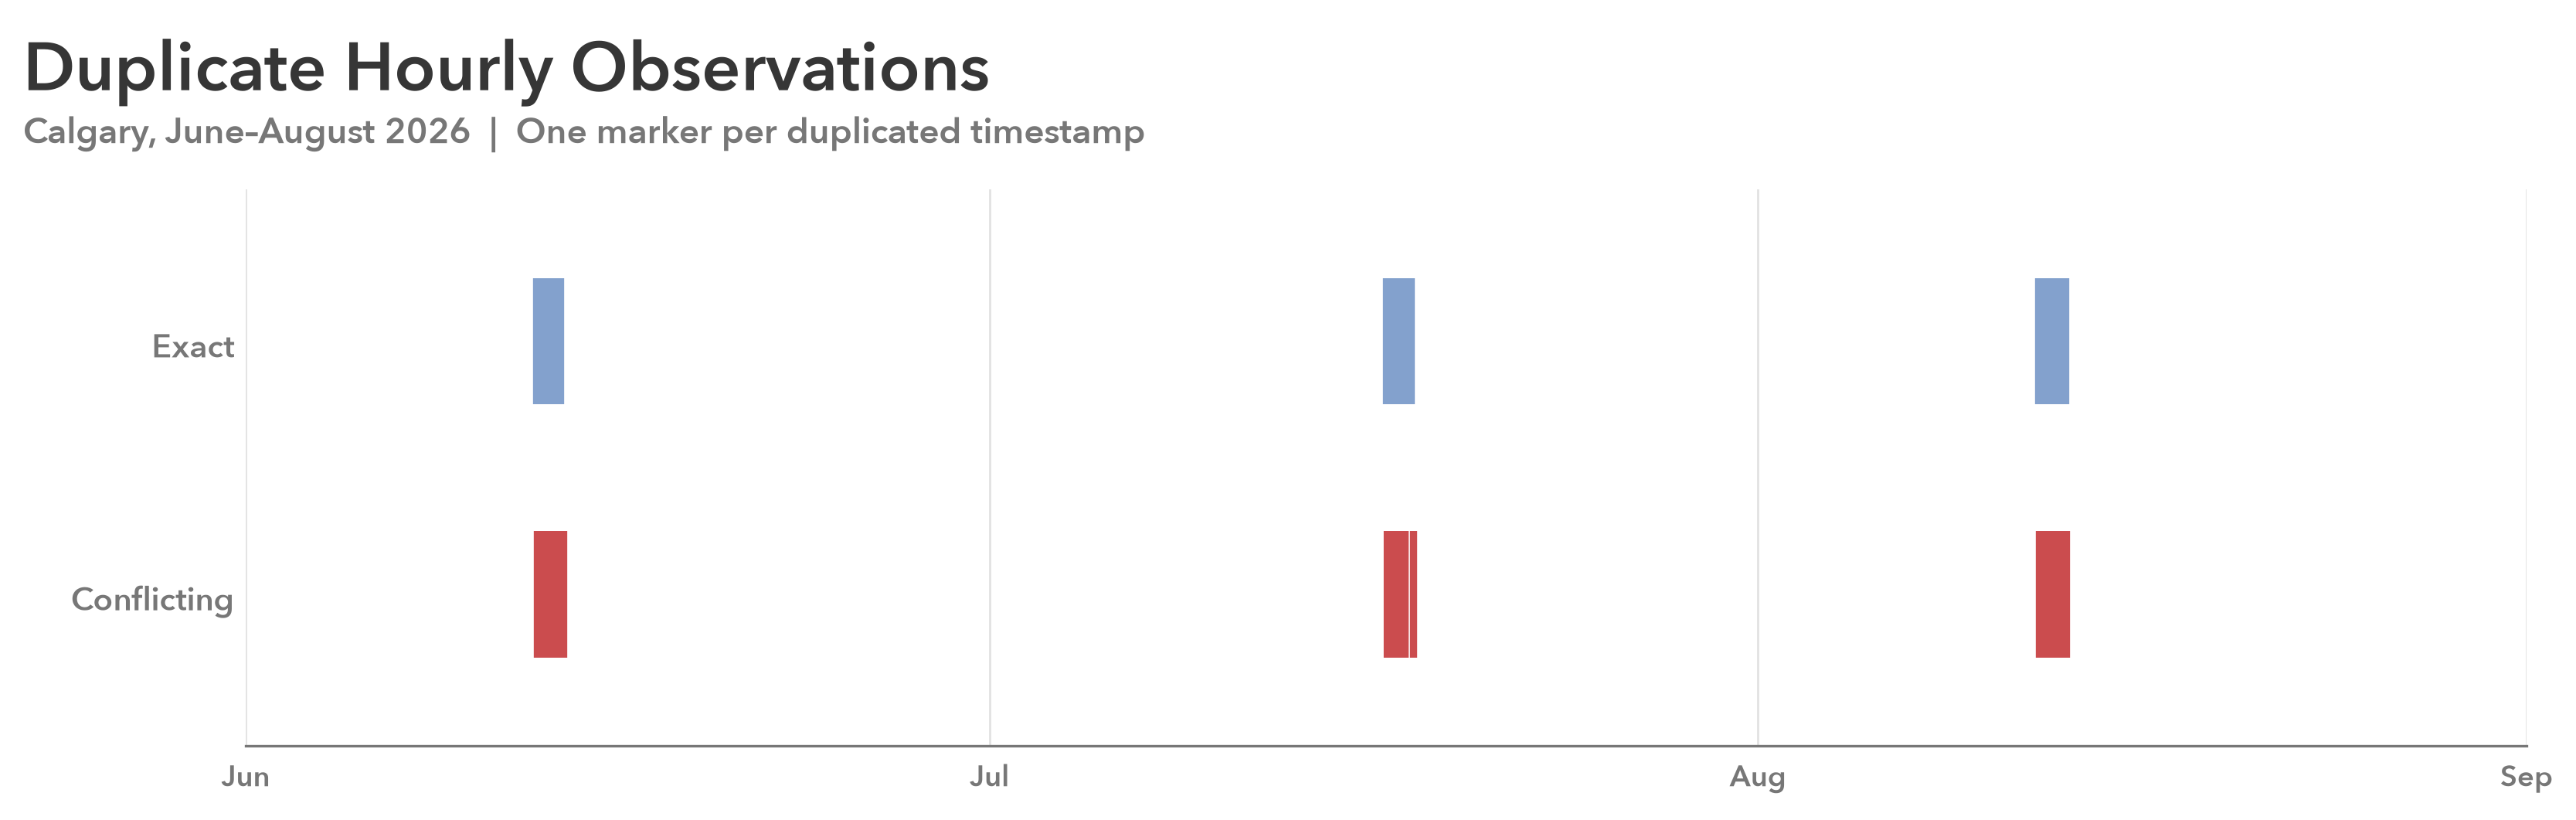

In [8]:
# Visualize Duplicates

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 600

fig, ax = plt.subplots(figsize = (12, 4), dpi = 300)

fig.subplots_adjust(
    left = 0.13,
    right = 0.95,
    top = 0.78,
    bottom = 0.18
)

STRUCTURE = "#777777"
BLUE = "#83A1CD"
RED = "#CB4C4E"
TITLE = "#363636"

# Plot

exact_times = variation.index[~conflicts]
conflicting_times = variation.index[conflicts]

ax.vlines(exact_times, ymin = 0.75, ymax = 1.25, color = BLUE, linewidth = 2)
ax.vlines(conflicting_times, ymin = -0.25, ymax = 0.25, color = RED, linewidth = 2)

# Emphasis

# Scale & Axes

ax.set_ylim(-0.6, 1.6)
ax.set_xlim(pd.Timestamp("2026-06-01", tz = "America/Edmonton"),
            pd.Timestamp("2026-09-01", tz = "America/Edmonton"))

ax.set_yticks([0, 1], ["Conflicting", "Exact"])

# Ticks

month_ticks = pd.date_range("2026-06-01", "2026-09-01", freq = "MS", tz = "America/Edmonton")

ax.set_xticks(month_ticks)
ax.set_xticklabels(["Jun", "Jul", "Aug", "Sep"])

ax.tick_params(axis = "x", labelsize = 9, length = 0, labelcolor = STRUCTURE)
ax.tick_params(axis = "y", labelsize = 10, length = 0, labelcolor = STRUCTURE)

# Styling

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(STRUCTURE)

ax.set_axisbelow(True)
ax.grid(axis = "x", color = STRUCTURE, linewidth = 0.7, alpha = 0.2)

# Composition

fig.suptitle("Duplicate Hourly Observations", x = 0.05, y = 0.96, ha = "left", va = "top", fontsize = 21, fontweight = 600, color = TITLE)

fig.text(0.05, 0.83, "Calgary, June–August 2026  |  One marker per duplicated timestamp", fontsize = 11, color = STRUCTURE)

# Output

fig.savefig("outputs/dirty.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()

In [9]:
# Clean

# Remove redundant exact duplicate records.
# Exclude timestamps with conflicting observations rather than arbitrarily selecting one measurement.

# The analysis will represent unique, unambiguous hourly observations.
# Excluded hours may affect the monthly percentages and their denominators.

deduped = df.drop_duplicates()
conflicting_times = deduped.loc[deduped["time"].duplicated(keep = False), "time"]
clean_df = deduped.loc[~deduped["time"].isin(conflicting_times)].copy()

print("Removed Exact Duplicates:", len(df) - len(deduped))
print("Excluded Conflicting Hours:", conflicting_times.nunique())
print("Remaining Duplicate Times:", clean_df["time"].duplicated().sum())

Removed Exact Duplicates: 43
Excluded Conflicting Hours: 42
Remaining Duplicate Times: 0


## Value Definitions

- **Daytime:** 08:00–19:59, Calgary local time (`America/Edmonton`), corresponding to hours 8–19 inclusive.
- **Hot-and-dry hour:** A daytime hour with temperature strictly above 25°C and relative humidity strictly below 40%.
- **Eligible hour**: A daytime hour with a unique, unambiguous observation remaining after cleaning, containing valid temperature and relative humidity measurements.
- **Monthly percentage:** The number of eligible daytime hours satisfying both weather conditions, divided by the total number of eligible daytime hours in that month, multiplied by 100.

In [10]:
# Transform

# Filter

filter_df = clean_df.loc[clean_df["time"].dt.hour.between(8, 19), ["time", "temperature_2m", "relative_humidity_2m"]].copy()

# Classify & Aggregate

output_df = (filter_df.assign(month = lambda x: x["time"].dt.month,
                              hot = lambda x: x["temperature_2m"].gt(25),
                              dry = lambda x: x["relative_humidity_2m"].lt(40))
                      .assign(hot_dry = lambda x: x["hot"] & x["dry"],
                              hot_only = lambda x: x["hot"] & ~x["dry"],
                              dry_only = lambda x: ~x["hot"] & x["dry"],
                              neither = lambda x: ~x["hot"] & ~x["dry"])
                      .groupby("month", as_index = False)
                      .agg(eligible_hours = ("time", "size"),
                           hot_dry_hours = ("hot_dry", "sum"),
                           hot_only_hours = ("hot_only", "sum"),
                           dry_only_hours = ("dry_only", "sum"),
                           neither_hours = ("neither", "sum"))
                      .assign(pct_hot_dry = lambda x: x["hot_dry_hours"].div(x["eligible_hours"]).mul(100),
                              pct_hot_only = lambda x: x["hot_only_hours"].div(x["eligible_hours"]).mul(100),
                              pct_dry_only = lambda x: x["dry_only_hours"].div(x["eligible_hours"]).mul(100),
                              pct_neither = lambda x: x["neither_hours"].div(x["eligible_hours"]).mul(100)))

output_df

,month,eligible_hours,hot_dry_hours,hot_only_hours,dry_only_hours,neither_hours,pct_hot_dry,pct_hot_only,pct_dry_only,pct_neither
0,6,350,1,0,72,277,0.285714,0.000000,20.571429,79.142857
1,7,366,125,29,13,199,34.153005,7.923497,3.551913,54.371585
2,8,361,47,15,72,227,13.019391,4.155125,19.944598,62.880886


In [11]:
# Classification Reconciliation

hour_columns = ["hot_dry_hours", "hot_only_hours", "dry_only_hours", "neither_hours"]
assert output_df[hour_columns].sum(axis = 1).eq(output_df["eligible_hours"]).all()

pct_columns = ["pct_hot_dry", "pct_hot_only", "pct_dry_only", "pct_neither"]
assert output_df[pct_columns].sum(axis = 1).sub(100).abs().lt(1e-9).all()

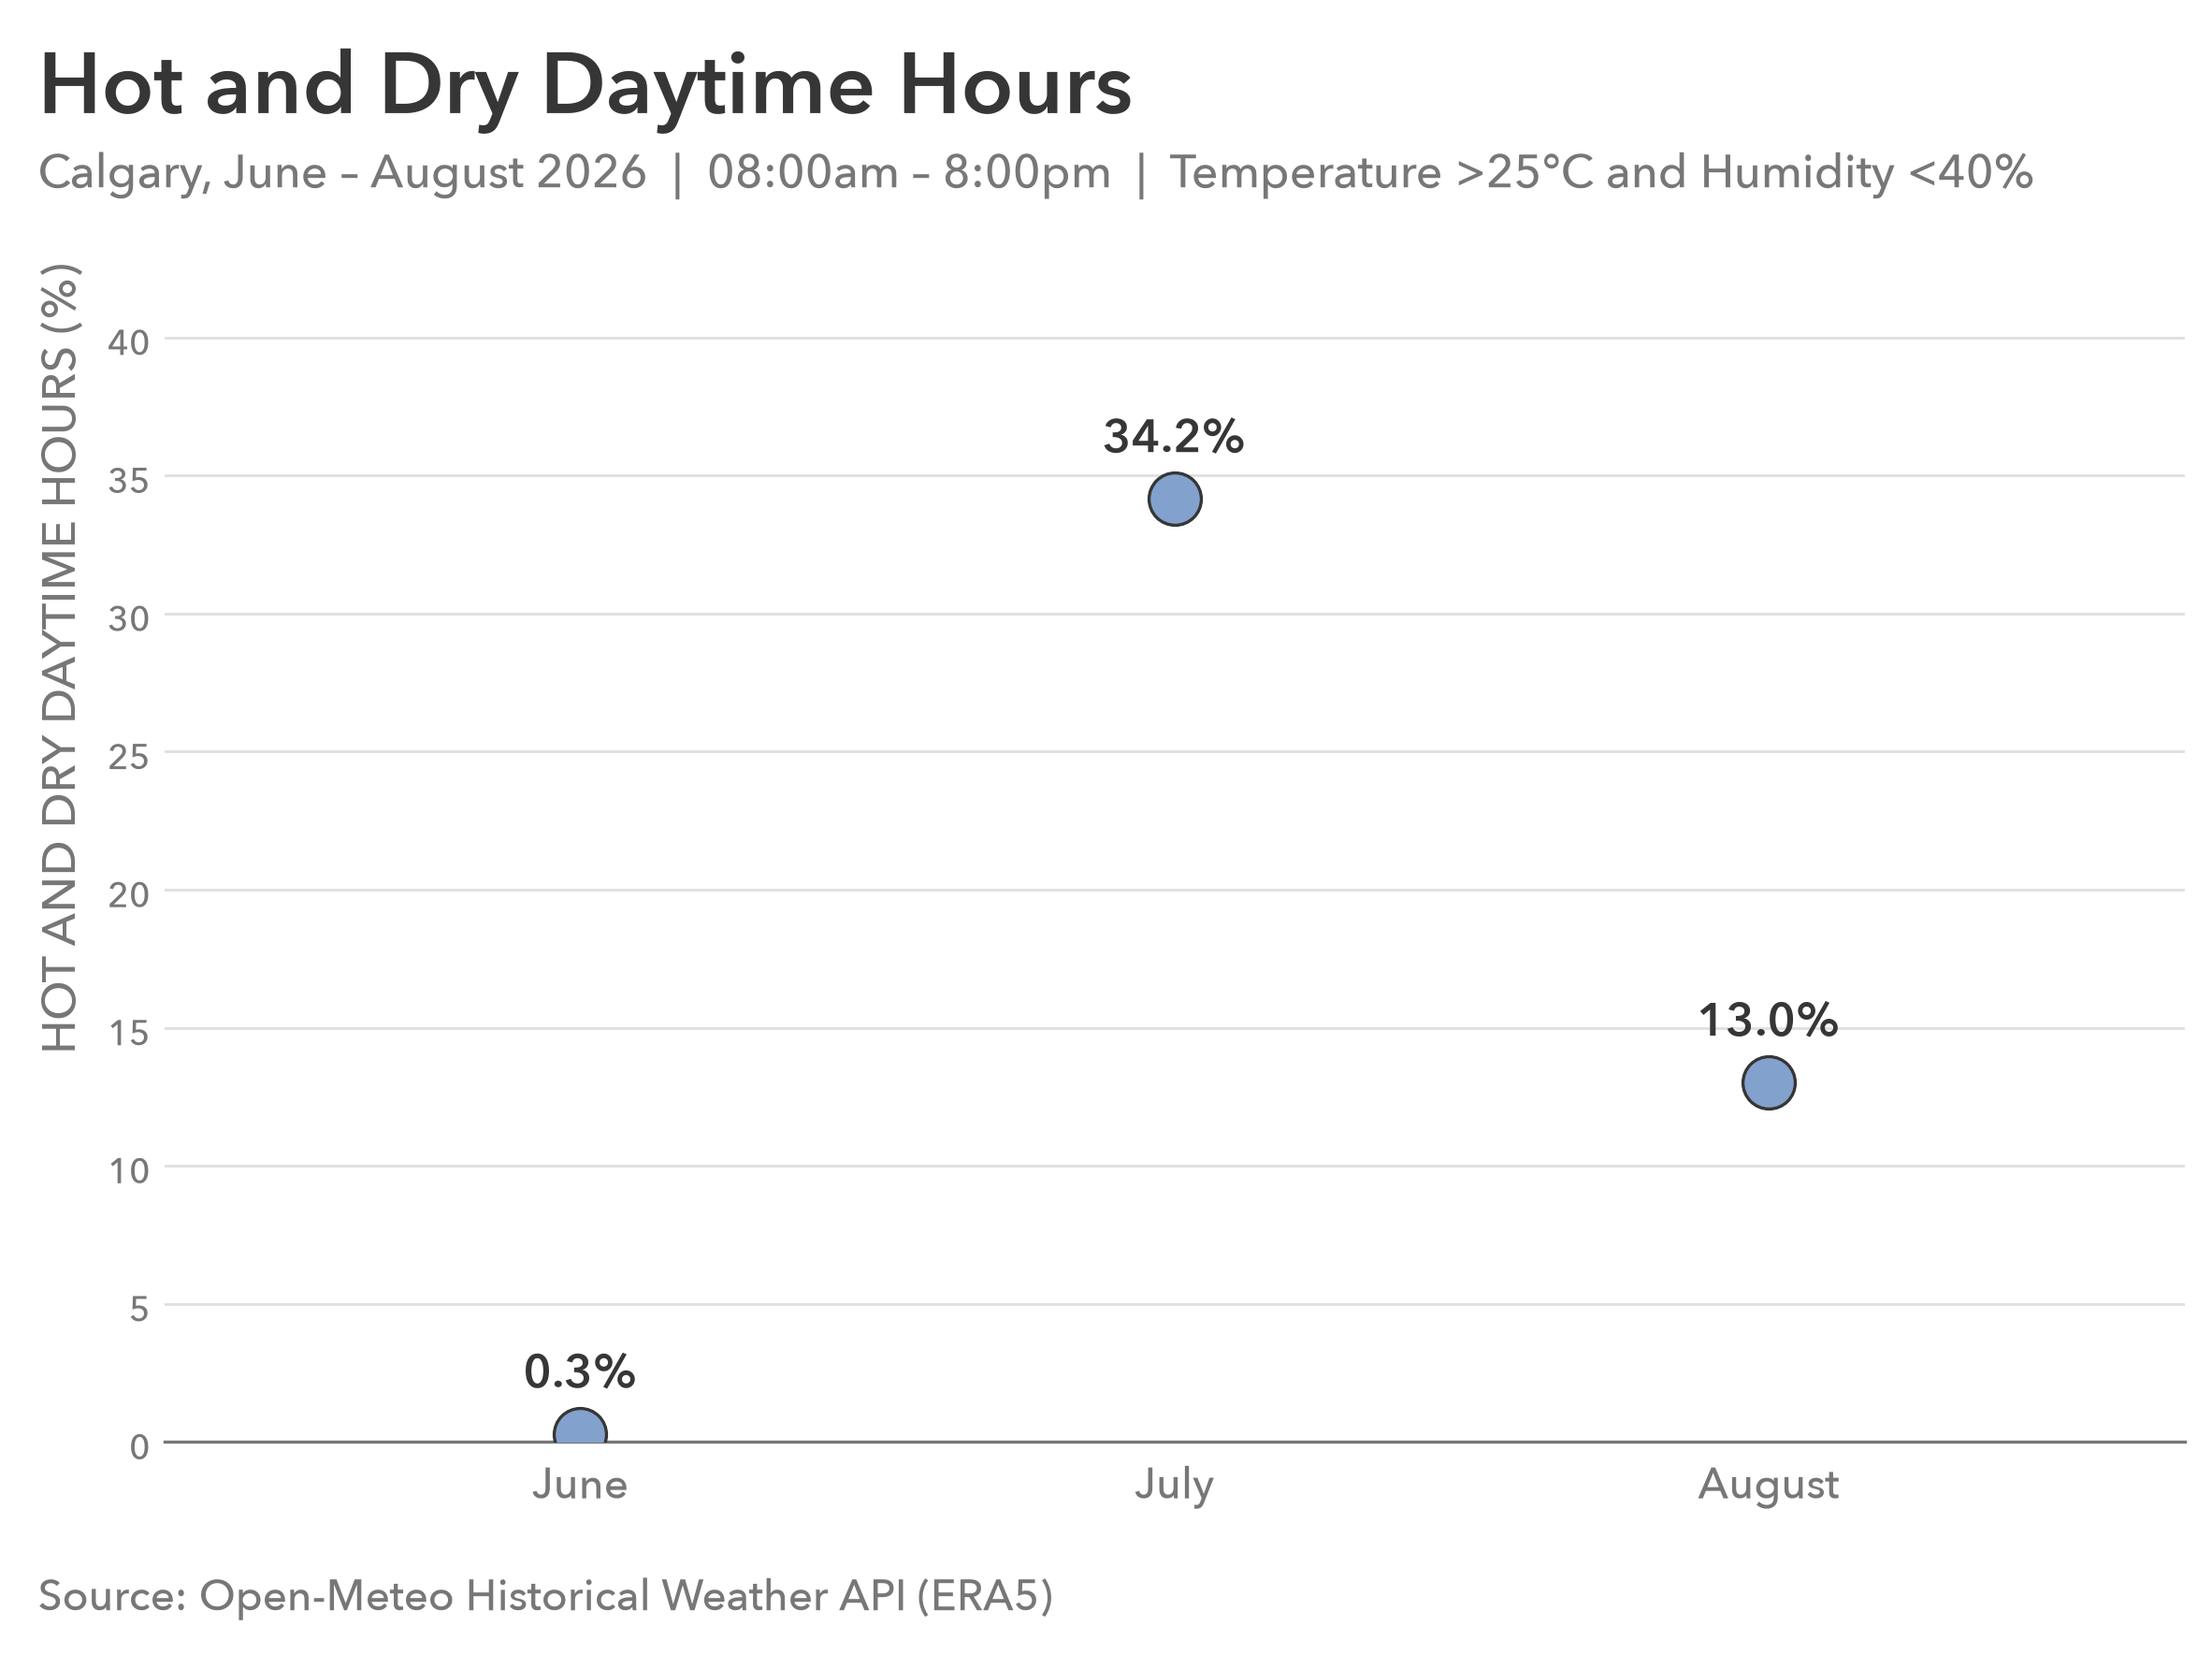

In [12]:
# Visualize

# Figure

plt.rcParams["font.family"] = "Avenir Next"
plt.rcParams["font.weight"] = 500

fig, ax = plt.subplots(figsize = (9, 6), dpi = 300)

fig.subplots_adjust(
    left = 0.10,
    right = 0.90,
    top = 0.80,
    bottom = 0.10
)

STRUCTURE = "#777777"
GRID = "#B3B3B3"
BLUE = "#83A1CD"
TITLE = "#363636"

# Plot

months = output_df["month"].map({6: "June", 7: "July", 8: "August"})

points = ax.scatter(months, output_df["pct_hot_dry"], s = 180, color = BLUE, edgecolors = TITLE, linewidths = 0.8, zorder = 3)

# Emphasis

for month, pct in zip(months, output_df["pct_hot_dry"]):
    ax.annotate(f"{pct:.1f}%", (month, pct), xytext = (0, 12), textcoords = "offset points", ha = "center", fontsize = 12, fontweight = 600, color = TITLE)

# Scale & Axes

ax.margins(x = 0.35)

ax.set_ylim(0, max(5, output_df["pct_hot_dry"].max() * 1.25))

ax.set_ylabel("HOT AND DRY DAYTIME HOURS (%)", loc = "top", fontsize = 12, fontweight = 500, color = STRUCTURE)

# Ticks

ax.tick_params(axis = "x", labelsize = 11, length = 0, labelcolor = STRUCTURE)
ax.tick_params(axis = "y", labelsize = 9, length = 0, labelcolor = STRUCTURE)

# Styling

ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(STRUCTURE)

ax.set_axisbelow(True)
ax.grid(axis = "y", color = GRID, linewidth = 0.7, alpha = 0.4)

# Composition

fig.suptitle("Hot and Dry Daytime Hours", x = 0.05, y = 0.94, ha = "left", va = "top", fontweight = 600, fontsize = 22, color = TITLE)

fig.text(0.05, 0.845, "Calgary, June – August 2026  |  08:00am – 8:00pm  |  Temperature >25°C and Humidity <40%", fontsize = 12, color = STRUCTURE)

fig.text(0.05, 0, "Source: Open-Meteo Historical Weather API (ERA5)", fontsize = 11, color = STRUCTURE)

# Output

fig.savefig("outputs/dotplot_hot-dry-daytime-hours-summer-2026.svg", bbox_inches = "tight", pad_inches = 0.1)
plt.show()